# County Presidential Participation Final Model Selection and Evaluation
**Author:** Mikaela Beck  
**Final capstone:** Required Capstone Project 24.1  
**Analysis date:** October 29, 2026

## 1. Objective and interpretation
Estimate 2024 presidential votes per 100 estimated adult county residents using eight demographic/prior political-context predictors. This is **supervised regression**. A prediction of 65 means about 65 presidential votes per 100 estimated adult residents, not a 65% probability that an individual votes.

The problem, source snapshots, geographic correction, and EDA are in Notebook 01. This notebook performs explicit hyperparameter grid searches for multiple models and reports geographic validation, uncertainty, predictive importance, error diagnostics, and limitations.

Module 20 was exploratory and its test results have been examined. We therefore do not relabel that test set as untouched. The final feature set and model grids are declared below; evaluation uses nested cross-validation with states as groups. Each outer test state's data are excluded from that fold's fitting and inner grid search. The study remains exploratory because features and scope were informed by earlier analysis. The validation estimates geographic transfer within 2024, not future-election forecasting.

In [1]:
from pathlib import Path
import json
import os

os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / 'data/processed').exists():
    ROOT = ROOT.parent
PROCESSED = ROOT / 'data/processed'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
SEED = 42
analysis = pd.read_csv(PROCESSED / 'county_analysis.csv', dtype={'county_fips': 'string'})
eda_summary = json.loads((REPORTS / 'eda_summary.json').read_text())
FEATURES = eda_summary['features']
LABELS = eda_summary['feature_labels']
assert len(FEATURES) == 8
assert not any('hispanic' in feature for feature in FEATURES)
assert analysis['county_fips'].is_unique
features = analysis[FEATURES]
outcome = analysis['participation_pct']
state_groups = analysis['state']
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 160})

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()
    plt.close()

def metrics_for(actual, predicted):
    return {'mae_pp': float(mean_absolute_error(actual, predicted)), 'rmse_pp': float(np.sqrt(mean_squared_error(actual, predicted))), 'r2': float(r2_score(actual, predicted))}

def readable_params(params):
    return {key: value.__class__.__name__ if key == 'model' else value for key, value in params.items()}

def model_name(estimator):
    return {'Ridge': 'Ridge regression', 'RandomForestRegressor': 'Random forest', 'HistGradientBoostingRegressor': 'Gradient boosting'}[estimator.__class__.__name__]

## 2. Models, grids, and scoring
**Primary metric: mean absolute error (MAE), in participation percentage points.** It answers how far the model misses the measured county participation proxy on average. Counties receive equal weight. RMSE emphasizes larger errors; R² compares squared error with a constant test-set mean and may be negative. These scores do not measure causal effects or individual voter accuracy.

Compare a training-mean baseline with Ridge regression, random forest, and histogram gradient boosting. Ridge supplies an interpretable regularized linear relationship; the tree models allow nonlinear relationships and interactions. Neural networks and classification are unnecessary for this modest tabular dataset and continuous outcome.

Each learned model is inside a Pipeline with median imputation and scaling. Imputation and scaling fit within each inner training fold. Scaling does not change tree split ordering but lets the same preprocessing pipeline be applied consistently. There are no nominal predictors requiring one-hot encoding: county/state identifiers stay out of the predictors. Gradient boosting's automatic early stopping is disabled so it cannot create a separate random row-based validation split inside a state-grouped experiment.

The candidate grids are fixed below. The combined GridSearchCV chooses both a model family and its hyperparameters within each outer training fold. A separate mean baseline uses only that outer training outcome. Search uses MAE, not the outer test outcome. We use one worker to keep execution reliable and reproducible.

In [2]:
pipeline = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('model', Ridge())])
parameter_grid = [
    {'model': [Ridge()], 'model__alpha': [0.1, 1.0, 10.0, 100.0, 1000.0]},
    {'model': [RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=1)], 'model__max_depth': [8, None], 'model__min_samples_leaf': [5, 15], 'model__max_features': [0.7, 1.0]},
    {'model': [HistGradientBoostingRegressor(max_iter=200, early_stopping=False, random_state=SEED)], 'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [7, 15], 'model__l2_regularization': [0.0, 1.0]},
]
grid_description = [{'family': model_name(grid['model'][0]), 'candidates': len(list(ParameterGrid(grid))), 'searched_parameters': str({key.replace('model__', ''): values for key, values in grid.items() if key != 'model'})} for grid in parameter_grid]
display(pd.DataFrame(grid_description))
assert sum(row['candidates'] for row in grid_description) == 21

,family,candidates,searched_parameters
0,Ridge regression,5,"{'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0]}"
1,Random forest,8,"{'max_depth': [8, None], 'min_samples_leaf': [..."
2,Gradient boosting,8,"{'learning_rate': [0.05, 0.1], 'max_leaf_nodes..."


## 3. Nested validation grouped by state
Five outer GroupKFold splits test on whole states/DC groups. Within each outer training set, three inner GroupKFold splits search all 21 candidates. The inner winner is refit on that outer training set and predicts the excluded outer states. Every county obtains one out-of-fold prediction. No state appears on both sides of an outer or inner split.

The main performance estimate is for this **combined selection procedure**. Family-specific predictions are also collected: in each outer fold, choose that family's best settings using inner CV only, refit on outer training data, and predict outer states. Family scores are informative comparisons; choosing a family after looking at their outer scores would add selection optimism, so the main report retains the procedure that makes the choice inside the inner folds.

After evaluation, a new five-fold grouped search on all available counties chooses a fitted model for describing the full dataset. Its inner CV score is a training-selection statistic; it is not substituted for the outer performance estimate. No future-election deployment is claimed.

In [3]:
outer_cv = GroupKFold(n_splits=5)
inner_cv = GroupKFold(n_splits=3)
oof = analysis[['county_fips', 'state', 'county_name', 'participation_pct', 'total_reconciliation_flag']].copy()
oof['outer_fold'] = -1
prediction_columns = ['Mean baseline', 'Ridge regression', 'Random forest', 'Gradient boosting', 'Nested selection procedure']
for prediction_column in prediction_columns:
    oof[prediction_column] = np.nan
fold_rows = []
search_rows = []
parameter_rows = []
importance_rows = []
state_split_rows = []
for fold_number, (train_indices, test_indices) in enumerate(outer_cv.split(features, outcome, state_groups), start=1):
    train_features, test_features = features.iloc[train_indices], features.iloc[test_indices]
    train_outcome, test_outcome = outcome.iloc[train_indices], outcome.iloc[test_indices]
    train_groups, test_groups = state_groups.iloc[train_indices], state_groups.iloc[test_indices]
    assert set(train_groups).isdisjoint(set(test_groups))
    for inner_train, inner_test in inner_cv.split(train_features, train_outcome, train_groups):
        assert set(train_groups.iloc[inner_train]).isdisjoint(set(train_groups.iloc[inner_test]))
    search = GridSearchCV(clone(pipeline), parameter_grid, scoring='neg_mean_absolute_error', cv=inner_cv, n_jobs=1, refit=True, error_score='raise', return_train_score=False)
    search.fit(train_features, train_outcome, groups=train_groups)
    combined_predictions = search.predict(test_features)
    oof.loc[test_indices, 'Nested selection procedure'] = combined_predictions
    oof.loc[test_indices, 'outer_fold'] = fold_number
    baseline = DummyRegressor(strategy='mean').fit(train_features.fillna(0), train_outcome)
    baseline_predictions = baseline.predict(test_features.fillna(0))
    oof.loc[test_indices, 'Mean baseline'] = baseline_predictions
    fold_rows.append({'fold': fold_number, 'model': 'Mean baseline', 'test_counties': len(test_indices), **metrics_for(test_outcome, baseline_predictions)})
    fold_rows.append({'fold': fold_number, 'model': 'Nested selection procedure', 'test_counties': len(test_indices), **metrics_for(test_outcome, combined_predictions)})
    selected_name = model_name(search.best_estimator_.named_steps['model'])
    parameter_rows.append({'fold': fold_number, 'selected_family': selected_name, 'inner_cv_mae_pp': float(-search.best_score_), 'parameters': json.dumps(readable_params(search.best_params_))})
    for candidate_number, candidate_params in enumerate(search.cv_results_['params']):
        search_rows.append({'outer_fold': fold_number, 'family': model_name(candidate_params['model']), 'parameters': json.dumps(readable_params(candidate_params)), 'inner_cv_mae_pp': float(-search.cv_results_['mean_test_score'][candidate_number]), 'inner_cv_fold_sd_pp': float(search.cv_results_['std_test_score'][candidate_number]), 'rank': int(search.cv_results_['rank_test_score'][candidate_number])})
    for family in ['Ridge regression', 'Random forest', 'Gradient boosting']:
        candidate_indices = [position for position, params in enumerate(search.cv_results_['params']) if model_name(params['model']) == family]
        family_best_index = max(candidate_indices, key=lambda position: search.cv_results_['mean_test_score'][position])
        family_params = search.cv_results_['params'][family_best_index]
        family_model = clone(pipeline).set_params(**family_params).fit(train_features, train_outcome)
        family_predictions = family_model.predict(test_features)
        oof.loc[test_indices, family] = family_predictions
        fold_rows.append({'fold': fold_number, 'model': family, 'test_counties': len(test_indices), **metrics_for(test_outcome, family_predictions)})
    permutation = permutation_importance(search.best_estimator_, test_features, test_outcome, scoring='neg_mean_absolute_error', n_repeats=8, random_state=SEED + fold_number, n_jobs=1)
    for feature, mean_increase, repeat_sd in zip(FEATURES, permutation.importances_mean, permutation.importances_std):
        importance_rows.append({'outer_fold': fold_number, 'feature': feature, 'label': LABELS[feature], 'test_counties': len(test_indices), 'mae_increase_pp': float(mean_increase), 'permutation_repeat_sd_pp': float(repeat_sd)})
    for state in sorted(test_groups.unique()):
        state_split_rows.append({'state': state, 'outer_test_fold': fold_number})
    print(f'Outer fold {fold_number}: {len(test_indices)} test counties; inner search selected {selected_name}; outer MAE {mean_absolute_error(test_outcome, combined_predictions):.3f} points')

assert oof[prediction_columns].notna().all().all()
assert oof['outer_fold'].between(1, 5).all()
assert oof.groupby('state')['outer_fold'].nunique().max() == 1
oof.to_csv(REPORTS / 'out_of_fold_predictions.csv', index=False)
fold_metrics = pd.DataFrame(fold_rows)
fold_metrics.to_csv(REPORTS / 'outer_fold_metrics.csv', index=False)
pd.DataFrame(search_rows).to_csv(REPORTS / 'nested_grid_search_results.csv', index=False)
pd.DataFrame(parameter_rows).to_csv(REPORTS / 'outer_fold_selected_parameters.csv', index=False)
pd.DataFrame(state_split_rows).to_csv(REPORTS / 'state_fold_assignments.csv', index=False)
pd.DataFrame(importance_rows).to_csv(REPORTS / 'outer_fold_permutation_importance.csv', index=False)
comparison_rows = [{'model': name, **metrics_for(outcome, oof[name]), 'predictions_outside_0_100': int((~oof[name].between(0, 100)).sum())} for name in prediction_columns]
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(REPORTS / 'nested_model_comparison.csv', index=False)
display(comparison.round(3))
display(pd.DataFrame(parameter_rows))

Outer fold 1: 619 test counties; inner search selected Gradient boosting; outer MAE 5.590 points


Outer fold 2: 619 test counties; inner search selected Gradient boosting; outer MAE 5.972 points


Outer fold 3: 619 test counties; inner search selected Gradient boosting; outer MAE 5.098 points


Outer fold 4: 623 test counties; inner search selected Gradient boosting; outer MAE 4.592 points


Outer fold 5: 619 test counties; inner search selected Gradient boosting; outer MAE 4.613 points


,model,mae_pp,rmse_pp,r2,predictions_outside_0_100
0,Mean baseline,8.049,10.082,-0.024,0
1,Ridge regression,5.536,7.101,0.492,0
2,Random forest,5.215,6.670,0.552,0
3,Gradient boosting,5.172,6.591,0.562,0
4,Nested selection procedure,5.172,6.591,0.562,0


,fold,selected_family,inner_cv_mae_pp,parameters
0,1,Gradient boosting,5.052867,"{""model"": ""HistGradientBoostingRegressor"", ""mo..."
1,2,Gradient boosting,5.182099,"{""model"": ""HistGradientBoostingRegressor"", ""mo..."
2,3,Gradient boosting,5.171934,"{""model"": ""HistGradientBoostingRegressor"", ""mo..."
3,4,Gradient boosting,5.321038,"{""model"": ""HistGradientBoostingRegressor"", ""mo..."
4,5,Gradient boosting,5.325601,"{""model"": ""HistGradientBoostingRegressor"", ""mo..."


## 4. Error interpretation and approximate uncertainty
Each reported error uses out-of-fold predictions from excluded states. The pooled MAE weights counties equally; the fold MAEs show sensitivity to geography. A county with an error of +5 points has actual participation five points higher than predicted. Predictions are not clipped to 0–100: any out-of-range prediction is counted as a model limitation rather than hidden.

To describe geographic uncertainty, resample the 49 state/DC groups with replacement 2,000 times, preserving all counties from a sampled group. Record the pooled MAE and paired baseline-minus-model MAE. The middle 95% of these draws is an **approximate state-resampling interval conditional on the saved predictions**. It reflects geographic composition, not ACS sampling uncertainty or the full uncertainty from refitting the entire search. Folds share training data, so this is not an exact independent-sample confidence interval. No causal significance test is performed.

**Procedure MAE:** 5.17 points; approximate state-resampling interval **4.70–5.63 points**. The baseline-minus-procedure error improvement is 2.88 points; approximate interval 2.27–3.48 points.

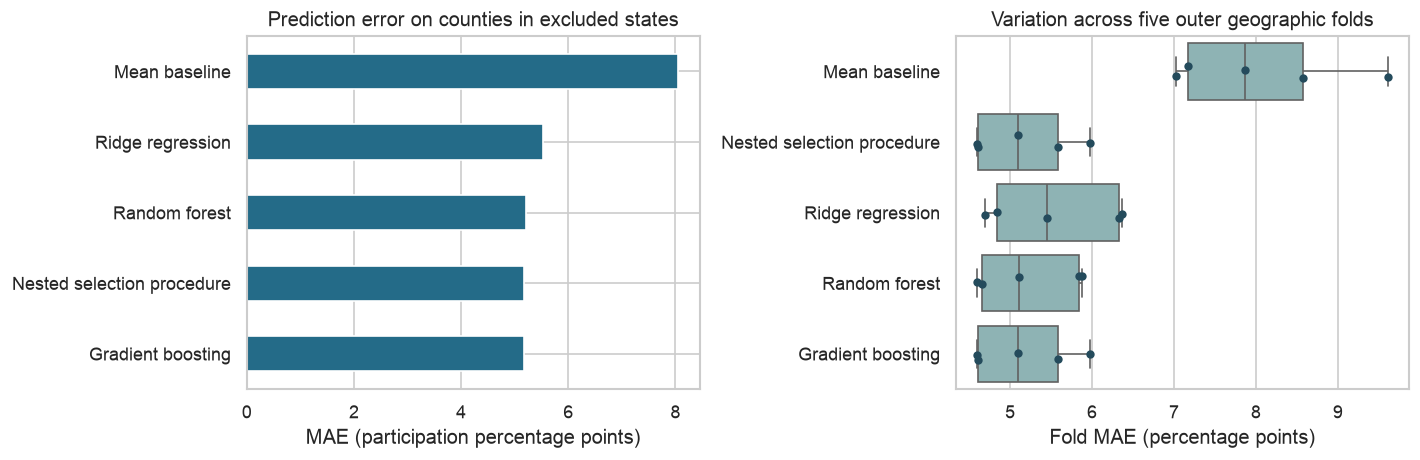

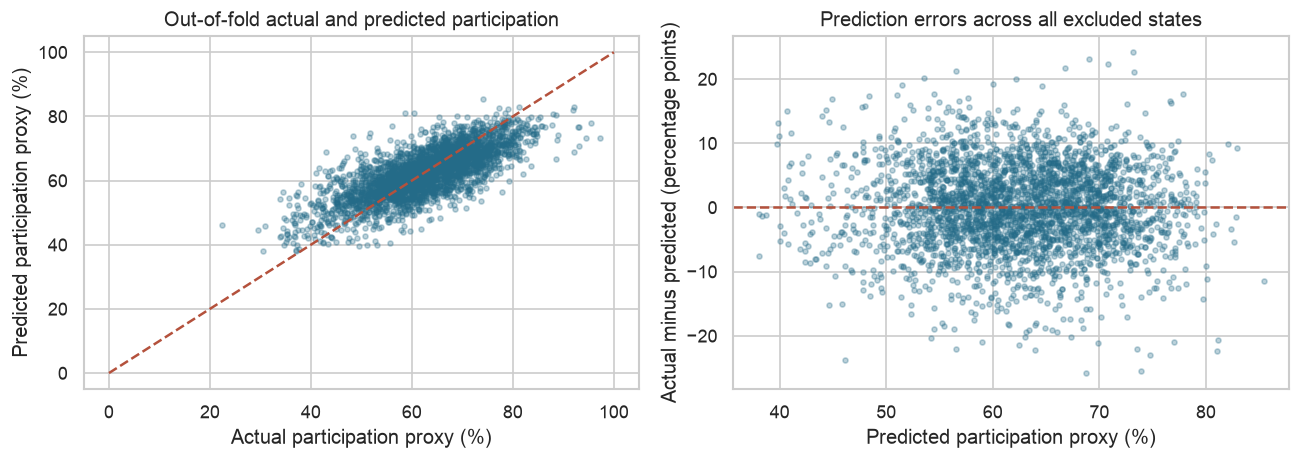

In [4]:
main_predictions = oof['Nested selection procedure']
baseline_predictions = oof['Mean baseline']
absolute_errors = (outcome - main_predictions).abs()
baseline_errors = (outcome - baseline_predictions).abs()
state_error_sums = pd.DataFrame({'state': state_groups, 'model_error': absolute_errors, 'baseline_error': baseline_errors}).groupby('state').agg(counties=('model_error', 'size'), model_error_sum=('model_error', 'sum'), baseline_error_sum=('baseline_error', 'sum'))
state_error_sums['model_mae_pp'] = state_error_sums['model_error_sum'] / state_error_sums['counties']
state_error_sums['baseline_mae_pp'] = state_error_sums['baseline_error_sum'] / state_error_sums['counties']
state_error_sums.to_csv(REPORTS / 'state_out_of_fold_errors.csv')
random_generator = np.random.default_rng(SEED)
state_draws = random_generator.integers(0, len(state_error_sums), size=(2000, len(state_error_sums)))
draw_counts = state_error_sums['counties'].to_numpy()[state_draws].sum(axis=1)
model_draw_mae = state_error_sums['model_error_sum'].to_numpy()[state_draws].sum(axis=1) / draw_counts
baseline_draw_mae = state_error_sums['baseline_error_sum'].to_numpy()[state_draws].sum(axis=1) / draw_counts
mae_interval = np.quantile(model_draw_mae, [0.025, 0.975])
improvement_interval = np.quantile(baseline_draw_mae - model_draw_mae, [0.025, 0.975])
uncertainty = {'draws': 2000, 'resampling_unit': 'state/DC group', 'model_mae_95pct_interval_pp': mae_interval.tolist(), 'baseline_minus_model_mae_95pct_interval_pp': improvement_interval.tolist(), 'interpretation': 'Approximate geographic resampling interval conditional on fixed out-of-fold predictions; not ACS or full model-refitting uncertainty.'}
(REPORTS / 'uncertainty.json').write_text(json.dumps(uncertainty, indent=2) + '\n')
display(Markdown(f"**Procedure MAE:** {absolute_errors.mean():.2f} points; approximate state-resampling interval **{mae_interval[0]:.2f}–{mae_interval[1]:.2f} points**. The baseline-minus-procedure error improvement is {float((baseline_errors - absolute_errors).mean()):.2f} points; approximate interval {improvement_interval[0]:.2f}–{improvement_interval[1]:.2f} points."))
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison.set_index('model')['mae_pp'].sort_values().plot.barh(ax=axes[0], color='#246b88')
axes[0].set(title='Prediction error on counties in excluded states', xlabel='MAE (participation percentage points)', ylabel='')
sns.boxplot(data=fold_metrics, x='mae_pp', y='model', color='#87b9bb', ax=axes[1])
sns.stripplot(data=fold_metrics, x='mae_pp', y='model', color='#244b5c', size=5, ax=axes[1])
axes[1].set(title='Variation across five outer geographic folds', xlabel='Fold MAE (percentage points)', ylabel='')
save_figure('06_nested_model_comparison.png')
residuals = outcome - main_predictions
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(outcome, main_predictions, s=9, alpha=0.3, color='#246b88')
axes[0].plot([0, 100], [0, 100], linestyle='--', color='#b4513c')
axes[0].set(title='Out-of-fold actual and predicted participation', xlabel='Actual participation proxy (%)', ylabel='Predicted participation proxy (%)')
axes[1].scatter(main_predictions, residuals, s=9, alpha=0.3, color='#246b88')
axes[1].axhline(0, linestyle='--', color='#b4513c')
axes[1].set(title='Prediction errors across all excluded states', xlabel='Predicted participation proxy (%)', ylabel='Actual minus predicted (percentage points)')
save_figure('07_out_of_fold_diagnostics.png')

## 5. Predictive interpretation and measurement checks
Permutation importance shuffles one feature only in an outer test fold and measures the increase in that fold's MAE. The chart combines outer results using county counts as weights. It describes predictive reliance of the selection procedure, not an intervention effect. Correlated predictors can share or hide importance; negative values mean the shuffle happened to improve prediction.

Source reconciliation and very small county populations are relevant measurement diagnostics. The fixed saved out-of-fold predictions are scored in these subsets without selecting or tuning a new model on them. These descriptive subgroup errors are not measures of individual fairness or instructions for demographic targeting.

,feature,label,mae_increase_pp,outer_fold_sd_pp
2,pct_age_18_29,Residents age 18–29 (%),1.067,0.266
3,pct_age_65_plus,Residents age 65+ (%),0.944,0.399
4,pct_bachelors_plus,Adults 25+ with bachelor degree or higher (%),0.776,0.306
5,pct_poverty,Residents below poverty threshold (%),0.724,0.147
0,log_population,County population (log10),0.232,0.151
1,median_household_income,Median household income (2024 dollars),0.220,0.170
6,prior_competitiveness,2020 two-party competitiveness (0–100),0.033,0.058
7,prior_dem_share_pct,2020 Democratic two-party share (%),0.021,0.033


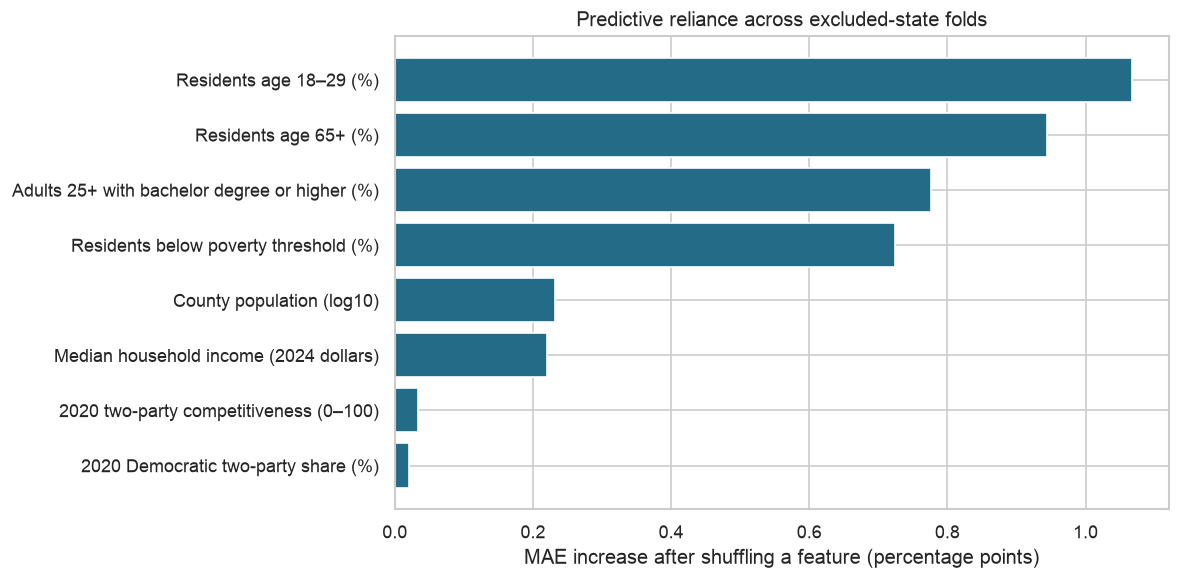

,subset,counties,mae_pp,rmse_pp,r2
0,Source totals reconcile,2972,5.206,6.633,0.561
1,Source candidate-sum discrepancy flagged,127,4.375,5.522,0.350
2,"Estimated adult population below 1,000",41,9.962,11.973,-0.198
3,"Estimated adult population at least 1,000",3058,5.108,6.488,0.563


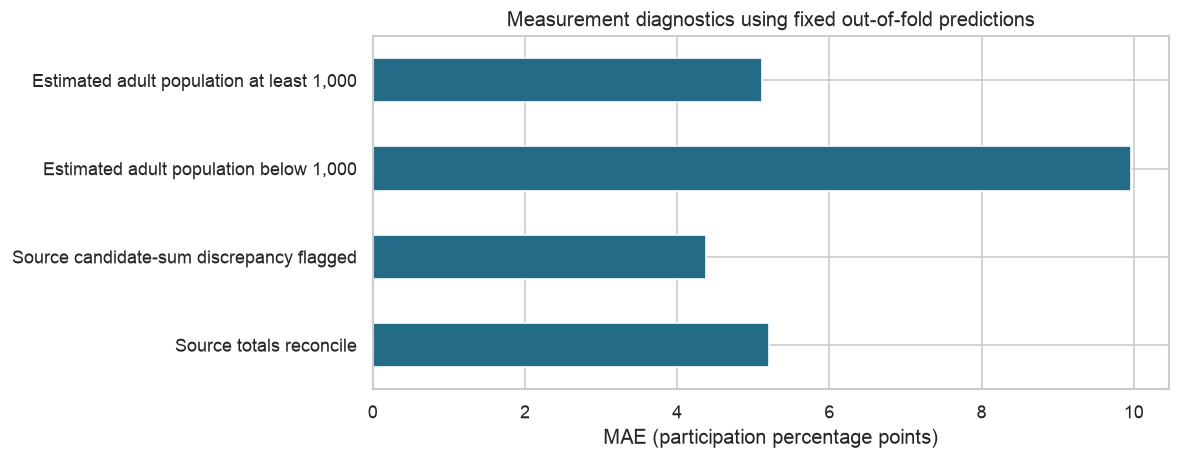

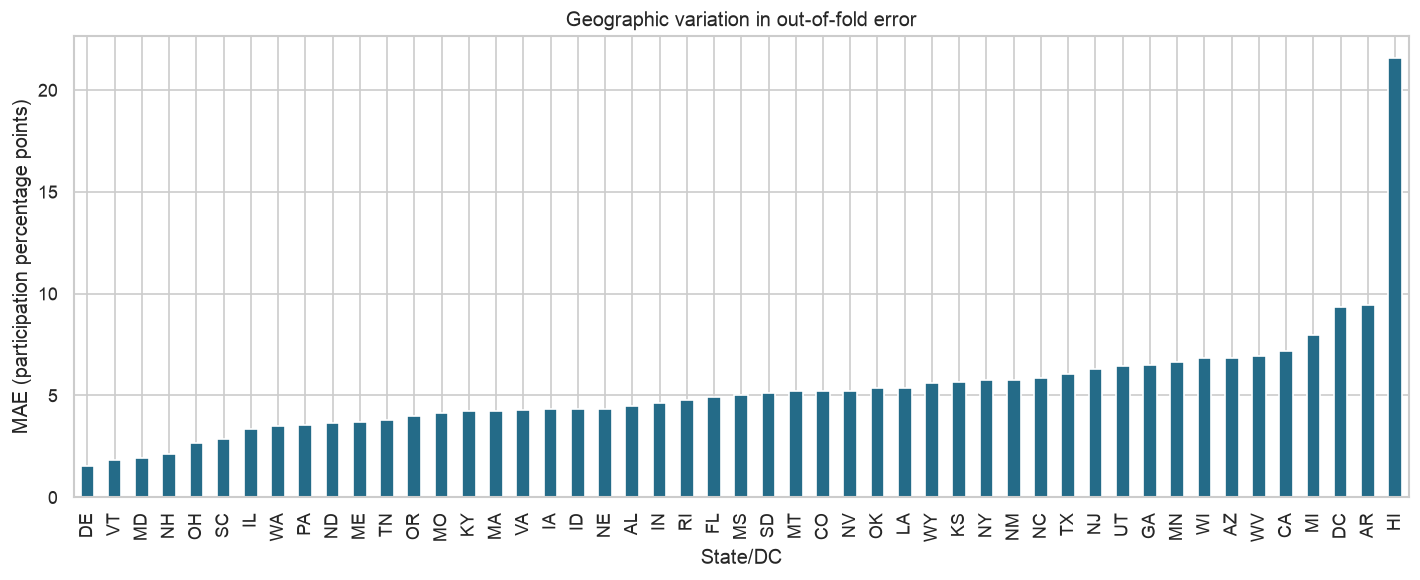

In [5]:
importance_by_fold = pd.DataFrame(importance_rows)
importance_summary = []
for feature, records in importance_by_fold.groupby('feature'):
    importance_summary.append({'feature': feature, 'label': LABELS[feature], 'mae_increase_pp': float(np.average(records['mae_increase_pp'], weights=records['test_counties'])), 'outer_fold_sd_pp': float(records['mae_increase_pp'].std(ddof=1))})
importance = pd.DataFrame(importance_summary).sort_values('mae_increase_pp', ascending=False)
importance.to_csv(REPORTS / 'permutation_importance.csv', index=False)
display(importance.round(3))
figure, axis = plt.subplots(figsize=(10, 5))
ordered = importance.sort_values('mae_increase_pp')
axis.barh(ordered['label'], ordered['mae_increase_pp'], color='#246b88')
axis.axvline(0, color='gray', linewidth=1)
axis.set(title='Predictive reliance across excluded-state folds', xlabel='MAE increase after shuffling a feature (percentage points)', ylabel='')
save_figure('08_predictive_importance.png')
measurement_rows = []
for description, subset in [
    ('Source totals reconcile', ~analysis['total_reconciliation_flag']),
    ('Source candidate-sum discrepancy flagged', analysis['total_reconciliation_flag']),
    ('Estimated adult population below 1,000', analysis['adult_population'] < 1000),
    ('Estimated adult population at least 1,000', analysis['adult_population'] >= 1000),
]:
    if subset.any():
        measurement_rows.append({'subset': description, 'counties': int(subset.sum()), **metrics_for(outcome[subset], main_predictions[subset])})
measurement_checks = pd.DataFrame(measurement_rows)
measurement_checks.to_csv(REPORTS / 'measurement_subgroup_errors.csv', index=False)
display(measurement_checks.round(3))
figure, axis = plt.subplots(figsize=(10, 4))
measurement_checks.set_index('subset')['mae_pp'].plot.barh(ax=axis, color='#246b88')
axis.set(title='Measurement diagnostics using fixed out-of-fold predictions', xlabel='MAE (participation percentage points)', ylabel='')
save_figure('09_measurement_diagnostics.png')
figure, axis = plt.subplots(figsize=(12, 5))
state_error_sums['model_mae_pp'].sort_values().plot.bar(ax=axis, color='#246b88')
axis.set(title='Geographic variation in out-of-fold error', xlabel='State/DC', ylabel='MAE (participation percentage points)')
save_figure('10_state_error_variation.png')

## 6. Full-data fitted model and reproducibility
After completing outer evaluation, fit the same declared model-selection procedure to all available counties using five-fold grouped CV. The search output records the final family and settings; it does not supply a new independent performance estimate. Save a compact candidate table and parameter JSON so the selection can be reproduced without a model binary. The notebook refits the model from local data.

In [6]:
final_search = GridSearchCV(clone(pipeline), parameter_grid, scoring='neg_mean_absolute_error', cv=GroupKFold(n_splits=5), n_jobs=1, refit=True, error_score='raise', return_train_score=False)
final_search.fit(features, outcome, groups=state_groups)
final_model_family = model_name(final_search.best_estimator_.named_steps['model'])
final_parameters = readable_params(final_search.best_params_)
full_search_rows = [{'family': model_name(params['model']), 'parameters': json.dumps(readable_params(params)), 'group_cv_mae_pp': float(-score), 'group_cv_fold_sd_pp': float(spread), 'rank': int(rank)} for params, score, spread, rank in zip(final_search.cv_results_['params'], final_search.cv_results_['mean_test_score'], final_search.cv_results_['std_test_score'], final_search.cv_results_['rank_test_score'])]
pd.DataFrame(full_search_rows).sort_values('rank').to_csv(REPORTS / 'full_data_grid_search_results.csv', index=False)
(REPORTS / 'final_model_parameters.json').write_text(json.dumps({'family': final_model_family, 'parameters': final_parameters, 'selection_cv_mae_pp': float(-final_search.best_score_), 'features': FEATURES, 'evaluation': 'Use nested selection procedure outer predictions, not this full-data inner score, for performance reporting.'}, indent=2) + '\n')
display(Markdown(f"**Full-data fitted family:** {final_model_family}. This final model is for retrospective description and reproducibility, not an approved pre-election forecasting deployment."))
display(pd.DataFrame(full_search_rows).sort_values('rank').head(5))
display(final_parameters)

**Full-data fitted family:** Gradient boosting. This final model is for retrospective description and reproducibility, not an approved pre-election forecasting deployment.

,family,parameters,group_cv_mae_pp,group_cv_fold_sd_pp,rank
13,Gradient boosting,"{""model"": ""HistGradientBoostingRegressor"", ""mo...",5.159360,0.539416,1
18,Gradient boosting,"{""model"": ""HistGradientBoostingRegressor"", ""mo...",5.166976,0.554473,2
14,Gradient boosting,"{""model"": ""HistGradientBoostingRegressor"", ""mo...",5.174847,0.556825,3
17,Gradient boosting,"{""model"": ""HistGradientBoostingRegressor"", ""mo...",5.179158,0.546807,4
15,Gradient boosting,"{""model"": ""HistGradientBoostingRegressor"", ""mo...",5.194743,0.527257,5


{'model': 'HistGradientBoostingRegressor',
 'model__l2_regularization': 0.0,
 'model__learning_rate': 0.05,
 'model__max_leaf_nodes': 7}

## 7. Final findings and recommended use
Read the generated findings below alongside the measurement and validation limits. The accompanying README translates them into a nontechnical report with proposed actions and next steps. No claim is made about the causal impact of campaign spending, canvassing, demographics, or individual behavior.

The practical recommendation is to improve and validate county participation measurement before using model residuals for substantive decisions. Source jurisdiction checks, denominator validation, and explicit geographic harmonization have demonstrated value here. A future forecasting study needs multiple election cycles and predictors available before election day; it also needs fresh chronological validation. Campaign spending requires a defined geographic allocation, and descriptive clustering is an optional later extension rather than an uncompleted rubric requirement.

In [7]:
main_metrics = comparison.set_index('model').loc['Nested selection procedure']
baseline_metrics = comparison.set_index('model').loc['Mean baseline']
improvement_pct = 100 * (baseline_metrics['mae_pp'] - main_metrics['mae_pp']) / baseline_metrics['mae_pp']
summary = {
    'analysis_date': '2026-10-29',
    'counties': len(analysis), 'states_and_dc': state_groups.nunique(),
    'feature_count': len(FEATURES), 'features': FEATURES,
    'outer_folds': 5, 'inner_folds': 3, 'candidates_per_search': 21,
    'nested_candidate_cv_fits': 5 * 3 * 21,
    'full_data_candidate_cv_fits': 5 * 21,
    'model_comparison': comparison.to_dict(orient='records'),
    'procedure_metrics': {key: float(main_metrics[key]) for key in ['mae_pp', 'rmse_pp', 'r2']},
    'baseline_metrics': {key: float(baseline_metrics[key]) for key in ['mae_pp', 'rmse_pp', 'r2']},
    'mae_reduction_pct': float(improvement_pct),
    'uncertainty': uncertainty,
    'outer_selected_families': pd.Series([row['selected_family'] for row in parameter_rows]).value_counts().to_dict(),
    'final_fitted_family': final_model_family,
    'final_parameters': final_parameters,
    'top_importance': importance.head(4).to_dict(orient='records'),
    'measurement_checks': measurement_checks.to_dict(orient='records'),
    'eda': eda_summary,
}
(REPORTS / 'final_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
display(Markdown(f'''### Executed final findings
- The corrected sample contains **{len(analysis):,} counties** in **{state_groups.nunique()} state/DC groups**.
- The nested selection procedure achieves **{main_metrics['mae_pp']:.2f} percentage-point MAE**, versus **{baseline_metrics['mae_pp']:.2f}** for the training-mean baseline: **{improvement_pct:.1f}% lower MAE**.
- Its pooled outer RMSE is **{main_metrics['rmse_pp']:.2f} points** and R² is **{main_metrics['r2']:.3f}**. The approximate geographic resampling interval for MAE is **{mae_interval[0]:.2f}–{mae_interval[1]:.2f} points**, conditional on these predictions.
- Full-data grouped grid search selects **{final_model_family}**. Its fitting settings are saved separately; outer validation remains the reported performance estimate.
- The largest predictive reliance is on **{', '.join(importance.head(3)['label'])}**. This is predictive reliance, not causal importance.
- The outcome remains a population-based proxy. FEC spending, individual outreach effects, verified prior turnout, and future-election forecasting have not been established by this study.
'''))

### Executed final findings
- The corrected sample contains **3,099 counties** in **49 state/DC groups**.
- The nested selection procedure achieves **5.17 percentage-point MAE**, versus **8.05** for the training-mean baseline: **35.7% lower MAE**.
- Its pooled outer RMSE is **6.59 points** and R² is **0.562**. The approximate geographic resampling interval for MAE is **4.70–5.63 points**, conditional on these predictions.
- Full-data grouped grid search selects **Gradient boosting**. Its fitting settings are saved separately; outer validation remains the reported performance estimate.
- The largest predictive reliance is on **Residents age 18–29 (%), Residents age 65+ (%), Adults 25+ with bachelor degree or higher (%)**. This is predictive reliance, not causal importance.
- The outcome remains a population-based proxy. FEC spending, individual outreach effects, verified prior turnout, and future-election forecasting have not been established by this study.
